# Разведочный анализ активности и возвращаемости игроков Cookie Cats

Cookie Cats — мобильная головоломка с внутриигровыми покупками. В опубликованном
эксперименте первый барьер продвижения располагался на 30-м или 40-м уровне.

**Бизнес-контекст.** Для обсуждения изменений игрового сценария необходимо понимать
поведение пользователей. Одно среднее значение может скрывать различия между
большинством игроков и небольшой высокоактивной группой, а также зависеть от
единичного экстремального наблюдения.

**Цель проекта** — исследовать распределение активности, проверить устойчивость
описательных показателей, изучить возвращаемость и определить направления дальнейшего исследования.

В рамках учебного проекта проведён разведочный анализ открытых данных о 90 189 игроках:
проверены пропуски и повторы, изучены распределение раундов и необычные значения,
концентрация активности, доля нулевых значений и сочетания возвращения на D1 и D7.
Сравнение экспериментальных версий рассматривается в дополнительном разделе. 
Исходный датасет Cookie Cats на Kaggle: https://www.kaggle.com/datasets/arpitdw/cokie-cats


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from IPython.display import display

In [2]:
files = list(Path("/kaggle/input").rglob("cookie_cats.csv"))

if len(files) != 1:
    raise ValueError("Подключи один датасет Cookie Cats через Add Input")

df = pd.read_csv(files[0])

df.head()

,userid,version,sum_gamerounds,retention_1,retention_7
0,116,gate_30,3,False,False
1,337,gate_30,38,True,False
2,377,gate_40,165,True,False
3,483,gate_40,1,False,False
4,488,gate_40,179,True,True


## Проверка качества данных

Проверим размеры таблицы, типы столбцов, наличие пропусков и повторяющихся игроков.

In [3]:
print("Количество строк:", df.shape[0])
print("Количество столбцов:", df.shape[1])

df.info()

Количество строк: 90189
Количество столбцов: 5
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   userid          90189 non-null  int64 
 1   version         90189 non-null  object
 2   sum_gamerounds  90189 non-null  int64 
 3   retention_1     90189 non-null  bool  
 4   retention_7     90189 non-null  bool  
dtypes: bool(2), int64(2), object(1)
memory usage: 2.2+ MB


In [4]:
print("Пропуски по столбцам:")
print(df.isna().sum())

print("Повторяющиеся игроки:")
print(df["userid"].duplicated().sum())

Пропуски по столбцам:
userid            0
version           0
sum_gamerounds    0
retention_1       0
retention_7       0
dtype: int64
Повторяющиеся игроки:
0


В таблице 90 189 игроков и пять столбцов. Пропуски и повторяющиеся идентификаторы
игроков не обнаружены. На этом этапе удаление или заполнение строк не потребовалось.
Эти проверки описывают доступную таблицу и не подтверждают корректность всей системы сбора данных.

## 1. Насколько неравномерно распределена активность игроков?

Изучим среднее, медиану, квартили и высокие перцентили.
Для выявления необычно больших значений используем правило IQR.

Граница Q3 + 1,5 × IQR является диагностическим ориентиром,
а не основанием автоматически удалять наблюдения.

In [5]:
activity_stats = df["sum_gamerounds"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.90, 0.95, 0.99]
)

display(activity_stats.to_frame("Раунды за 14 дней"))

q1 = df["sum_gamerounds"].quantile(0.25)
q3 = df["sum_gamerounds"].quantile(0.75)

iqr = q3 - q1
upper_bound = q3 + 1.5 * iqr

above_bound = df["sum_gamerounds"] > upper_bound

print(f"IQR: {iqr:.0f} раундов")
print(f"Верхняя диагностическая граница: {upper_bound:.0f} раундов")
print(
    f"Выше границы: {above_bound.sum():,} игроков "
    f"({above_bound.mean():.2%})"
)

,Раунды за 14 дней
count,90189.000000
mean,51.872457
std,195.050858
min,0.000000
25%,5.000000
50%,16.000000
75%,51.000000
90%,134.000000
95%,221.000000
99%,493.000000


IQR: 46 раундов
Верхняя диагностическая граница: 120 раундов
Выше границы: 10,177 игроков (11.28%)


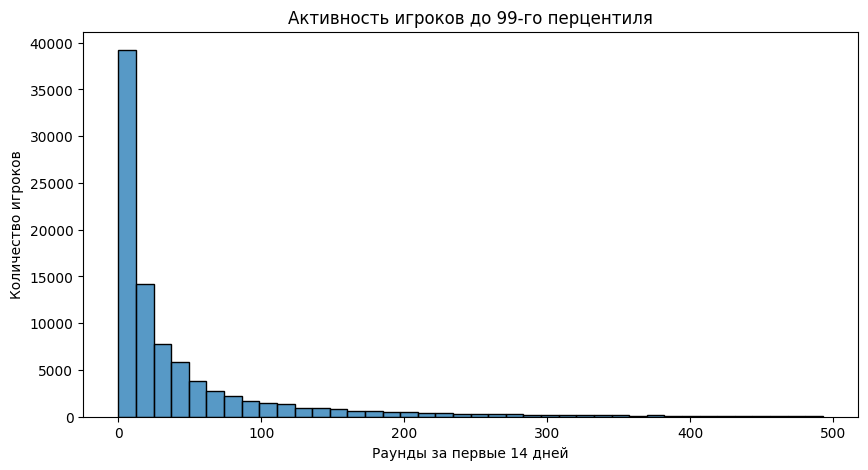

In [6]:
limit = df["sum_gamerounds"].quantile(0.99)
plot_df = df[df["sum_gamerounds"] <= limit]

plt.figure(figsize=(10, 5))

sns.histplot(
    data=plot_df,
    x="sum_gamerounds",
    bins=40
)

plt.title("Активность игроков до 99-го перцентиля")
plt.xlabel("Раунды за первые 14 дней")
plt.ylabel("Количество игроков")
plt.show()

Медиана составляет 16 раундов, 75-й перцентиль — 51,
90-й — 134, 95-й — 221, 99-й — 493.

Активность распределена неравномерно: большинство игроков играет
относительно мало, а меньшая часть создаёт длинный правый хвост.

IQR равен 46. Выше диагностической границы 120 раундов находятся
10 177 игроков, или 11,28% выборки. Эти значения требуют изучения,
но не считаются доказанными ошибками.

Гистограмма показывает участок до 99-го перцентиля.
Ограничение применяется только к рисунку: основная таблица сохранена полностью.

## 2. Почему среднее сильно отличается от медианы?

Рассмотрим наиболее активных игроков и проверим устойчивость показателей
в отдельном сценарии без максимального наблюдения.

Основная таблица сохраняет всех пользователей.


In [7]:
display(df.nlargest(5, "sum_gamerounds"))

max_rounds = df["sum_gamerounds"].max()

without_max = df.loc[
    df["sum_gamerounds"] < max_rounds
]

overall_sensitivity = pd.DataFrame({
    "Сценарий": ["Все игроки", "Без максимума"],
    "Игроков": [len(df), len(without_max)],
    "Среднее": [
        df["sum_gamerounds"].mean(),
        without_max["sum_gamerounds"].mean()
    ],
    "Медиана": [
        df["sum_gamerounds"].median(),
        without_max["sum_gamerounds"].median()
    ]
})

display(overall_sensitivity.round(2))

comparison = pd.DataFrame({
    "Среднее, все игроки":
        df.groupby("version")["sum_gamerounds"].mean(),
    "Среднее, без максимума":
        without_max.groupby("version")["sum_gamerounds"].mean(),
    "Медиана, все игроки":
        df.groupby("version")["sum_gamerounds"].median()
})

display(comparison.round(3))

,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True
7912,871500,gate_30,2961,True,True
29417,3271615,gate_40,2640,True,False
43671,4832608,gate_30,2438,True,True
48188,5346171,gate_40,2294,True,True


,Сценарий,Игроков,Среднее,Медиана
0,Все игроки,90189,51.87,16.0
1,Без максимума,90188,51.32,16.0


,"Среднее, все игроки","Среднее, без максимума","Медиана, все игроки"
version,,,
gate_30,52.456,51.342,17.0
gate_40,51.299,51.299,16.0


Среднее число раундов составляет 51,87, медиана — 16.
После исключения максимального значения только в диагностическом
сценарии среднее снижается до 51,32, а медиана остаётся равной 16.

Большой разрыв среднего и медианы связан с длинным правым хвостом
в целом, а не только с одним игроком.

При этом максимум существенно влияет на сравнение групп:
разница средних сокращается примерно с 1,16 до 0,04 раунда.

Происхождение значения 49 854 требует проверки по исходным событиям.
По имеющейся таблице признать его ошибкой нельзя.

## 3. Какую долю всех раундов сыграли самые активные пользователи?

Выделим примерно 1%, 5% и 10% игроков с наибольшим числом раундов.
Число игроков округляем вверх: ceil(N × доля). Поэтому фактическая доля может
быть немного больше номинальной. При равной активности на границе выбираются
первые строки; одинаковое число раундов не меняет итоговую сумму выбранной группы.

,Группа,Игроков,Раундов,"Доля всех раундов, %"
0,Топ 1%,902,704323,15.06
1,Топ 5%,4510,1841353,39.36
2,Топ 10%,9019,2612600,55.84


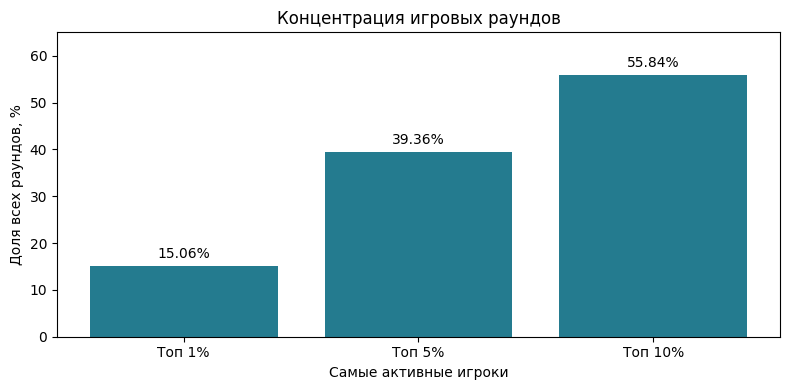

In [8]:
from math import ceil

total_rounds = df["sum_gamerounds"].sum()
concentration_rows = []

for share in [0.01, 0.05, 0.10]:
    top_n = ceil(len(df) * share)
    top_players = df.nlargest(top_n, "sum_gamerounds")

    concentration_rows.append({
        "Группа": f"Топ {share:.0%}",
        "Игроков": top_n,
        "Раундов": int(top_players["sum_gamerounds"].sum()),
        "Доля всех раундов, %":
            100 * top_players["sum_gamerounds"].sum() / total_rounds
    })

concentration = pd.DataFrame(concentration_rows)

display(concentration.round(2))

fig, ax = plt.subplots(figsize=(8, 4))

ax.bar(
    concentration["Группа"],
    concentration["Доля всех раундов, %"],
    color="#247B8F"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_ylim(0, 65)
ax.set_title("Концентрация игровых раундов")
ax.set_xlabel("Самые активные игроки")
ax.set_ylabel("Доля всех раундов, %")

plt.tight_layout()
plt.show()

Примерно 1% самых активных игроков — 902 человека —
сыграл 15,06% всех раундов.

На 5% пользователей приходится 39,36% раундов,
а на 10% — 55,84%.

Небольшая по численности группа создаёт большую долю игровой активности.
Это не означает такую же концентрацию выручки: платежи в данных отсутствуют.

Группы вложены друг в друга: топ 1% входит в топ 5% и топ 10%.
Поэтому показанные доли нельзя складывать.

## 4. Сколько игроков имеют нулевую активность?

Посчитаем число и долю пользователей, не сыгравших ни одного раунда.
Описательно сравним этот показатель между версиями.

In [9]:
zero_mask = df["sum_gamerounds"].eq(0)

zero_count = int(zero_mask.sum())
zero_share_pct = zero_mask.mean() * 100

print(
    f"Нулевая активность: {zero_count:,} игроков "
    f"({zero_share_pct:.2f}%)"
)

zero_by_version = (
    df.assign(zero_rounds=zero_mask)
    .groupby("version")
    .agg(
        players=("userid", "size"),
        zero_players=("zero_rounds", "sum"),
        zero_share=("zero_rounds", "mean")
    )
)

zero_by_version["zero_share_pct"] = (
    zero_by_version["zero_share"] * 100
)

display(
    zero_by_version[
        ["players", "zero_players", "zero_share_pct"]
    ].round(2)
)

Нулевая активность: 3,994 игроков (4.43%)


,players,zero_players,zero_share_pct
version,,,
gate_30,44700,1937,4.33
gate_40,45489,2057,4.52


Нулевую активность имеют 3 994 игрока — 4,43% выборки.

В группе gate_30 доля составляет 4,33%, в gate_40 — 4,52%.
Это описательное сравнение без вывода о причине различия.

Нулевые значения могут быть связаны с отсутствием начала игры,
техническими проблемами или особенностями учёта событий.
По доступным столбцам установить причину нельзя.

Для дальнейшего исследования нужны события установки, первого запуска,
обучения и начала первого раунда.
Эти пользователи сохранены в основной выборке.

## 5. Как сочетаются возвращение на D1 и D7?

Рассмотрим четыре сочетания двух признаков возвращения.
Это не последовательная воронка: игрок может пропустить D1
и вернуться на D7.

Доли в таблице считаются от всех игроков.

,Сочетание,Игроков,"Доля всех игроков, %"
0,"Не вернулся ни на D1, ни на D7",46437,51.49
1,Только на D7,3599,3.99
2,Только на D1,26971,29.90
3,На D1 и D7,13182,14.62


D7 среди вернувшихся на D1: 32.83%
D7 среди не вернувшихся на D1: 7.19%


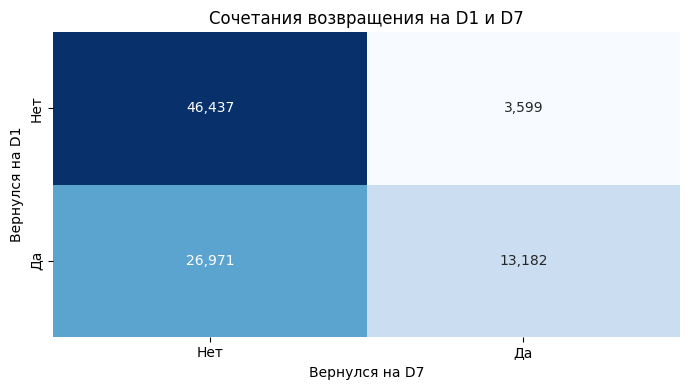

In [10]:
retention_cross = pd.crosstab(
    df["retention_1"],
    df["retention_7"]
).reindex(
    index=[False, True],
    columns=[False, True],
    fill_value=0
)

retention_combinations = pd.DataFrame({
    "Сочетание": [
        "Не вернулся ни на D1, ни на D7",
        "Только на D7",
        "Только на D1",
        "На D1 и D7"
    ],
    "Игроков": [
        retention_cross.loc[False, False],
        retention_cross.loc[False, True],
        retention_cross.loc[True, False],
        retention_cross.loc[True, True]
    ]
})

retention_combinations["Доля всех игроков, %"] = (
    retention_combinations["Игроков"] / len(df) * 100
)

display(retention_combinations.round(2))

conditional_d7 = retention_cross.div(
    retention_cross.sum(axis=1),
    axis=0
)[True] * 100

print(
    f"D7 среди вернувшихся на D1: "
    f"{conditional_d7.loc[True]:.2f}%"
)

print(
    f"D7 среди не вернувшихся на D1: "
    f"{conditional_d7.loc[False]:.2f}%"
)

plt.figure(figsize=(7, 4))

sns.heatmap(
    retention_cross,
    annot=True,
    fmt=",d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Нет", "Да"],
    yticklabels=["Нет", "Да"]
)

plt.title("Сочетания возвращения на D1 и D7")
plt.xlabel("Вернулся на D7")
plt.ylabel("Вернулся на D1")

plt.tight_layout()
plt.show()

Ни на D1, ни на D7 не вернулись 46 437 игроков — 51,49%.
Только на D1 вернулись 26 971 — 29,90%.
Только на D7 — 3 599 — 3,99%.
На оба дня — 13 182 — 14,62%.

Отсутствие возвращения в эти два дня не означает,
что пользователь не играл в другие дни.

Среди вернувшихся на D1 доля возвращения на D7 равна 32,83%.
Среди не вернувшихся на D1 — 7,19%.

Эта связь не доказывает, что сам возврат на D1 вызывает возврат на D7.

## 6. Какие особенности требуют дальнейшего исследования?

| Наблюдение | Вопрос для проверки | Необходимые данные |
|---|---|---|
| Максимум 49 854 раунда | Реальная активность, особый аккаунт или ошибка учёта? | Время событий, длительность сессий, признаки тестовых аккаунтов |
| 4,43% игроков имеют ноль раундов | Где возникает потеря между установкой и первым раундом? | Первый запуск, обучение, начало раунда, технические ошибки |
| 10% игроков создают 55,84% раундов | Чем отличается высокоактивный сегмент и какую ценность он создаёт? | История сессий, платежи, канал привлечения |
| Возврат на D7 связан с возвратом на D1 | Какие ранние действия связаны с дальнейшей вовлечённостью? | Действия до D1, когорты установки, отдельный эксперимент для проверки причин |
| Удержание различается между версиями | Можно ли считать различие эффектом барьера? | Протокол назначения групп, полнота наблюдений, события достижения барьера |

Перечисленные объяснения являются гипотезами, а не установленными причинами.

Число раундов за 14 дней нельзя считать исходным независимым фактором
возврата на D7: периоды измерения пересекаются, а активность сама может
зависеть от возвращения и назначенной версии.

## Выводы разведочного анализа

1. Базовые проверки данных пройдены: пропусков и повторяющихся
   идентификаторов игроков не обнаружено.

2. Активность распределена неравномерно. Медиана составляет 16 раундов,
   среднее — 51,87. Распределение имеет длинный правый хвост.

3. Максимальное наблюдение существенно влияет на сравнение средних
   между версиями, но не объясняет весь разрыв среднего и медианы.

4. Примерно 1% игроков создаёт 15,06% раундов, а 10% — 55,84%.
   Для описания аудитории важно учитывать концентрацию активности.

5. Нулевую активность имеют 4,43% игроков.
   Для исследования причин нужны события первого запуска и обучения.

6. D1 и D7 являются отдельными признаками возвращения.
   Их нельзя интерпретировать как последовательную воронку.

Практическое значение: при мониторинге поведения полезно отслеживать
медиану и перцентили вместе со средним, долю нулевой активности,
концентрацию раундов и сочетания возвращения.

Для решения об изменении барьера необходим дополнительный анализ
эксперимента. Выручка и причины ухода в этом наборе данных не измерены.

## Дополнительный раздел. Сравнение двух версий игры

Ниже рассматриваются различия опубликованных экспериментальных групп.
Основная часть проекта посвящена разведочному анализу.

In [11]:
summary = df.groupby("version").agg(
    players=("userid", "count"),
    mean_rounds=("sum_gamerounds", "mean"),
    median_rounds=("sum_gamerounds", "median"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
)

summary

,players,mean_rounds,median_rounds,retention_1,retention_7
version,,,,,
gate_30,44700,52.456264,17.0,0.448188,0.190201
gate_40,45489,51.298776,16.0,0.442283,0.182000


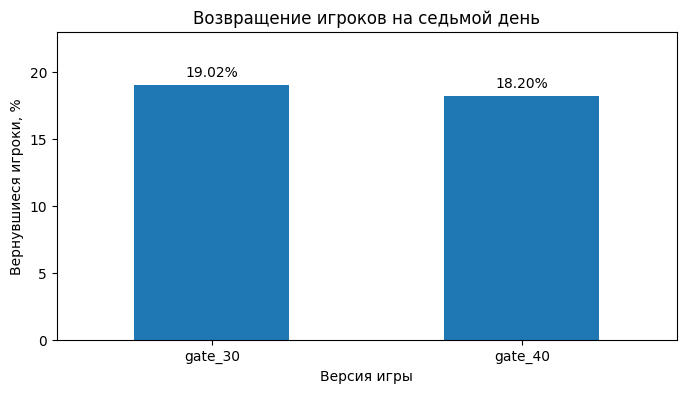

In [12]:
retention = (
    df.groupby("version")["retention_7"]
    .mean()
    .mul(100)
)

ax = retention.plot(kind="bar", rot=0, figsize=(8, 4))
ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)
ax.set_ylim(0, 23)

plt.title("Возвращение игроков на седьмой день")
plt.xlabel("Версия игры")
plt.ylabel("Вернувшиеся игроки, %")
plt.show()

In [13]:
difference = retention["gate_40"] - retention["gate_30"]

print("Разница gate_40 − gate_30:")
print(round(difference, 2), "процентного пункта")

Разница gate_40 − gate_30:
-0.82 процентного пункта


## Гипотеза для удержания D7

H0: вероятность возвращения на седьмой день
одинакова в обеих версиях игры.

H1: вероятность возвращения различается.

Для этой первой проверки используем уровень значимости 0.05.
Удержание D1 пока рассматриваем описательно.

In [14]:
from scipy.stats import chi2_contingency

contingency_table = pd.crosstab(
    df["version"],
    df["retention_7"]
)

result = chi2_contingency(
    contingency_table,
    correction=False
)

print("p-value:", result.pvalue)

p-value: 0.0015542499756142805


### Интерпретация дополнительного анализа

В `gate_30` удержание D7 составляет 19,02%, в `gate_40` — 18,20%.
Разность `gate_40 - gate_30` равна −0,82 п.п. Получено p-value ≈ 0,00155:
при предпосылках χ²-критерия гипотеза одинакового удержания отвергается на уровне 0,05.
Проверка предполагает независимых игроков и достаточно большие ожидаемые частоты.

p-value не является вероятностью истинности H0 и не устанавливает причину различия.
Перед причинной интерпретацией необходимо проверить протокол назначения групп,
запланированную пропорцию и полноту окна наблюдений. Размеры групп- 44 700 и 45 489;
допустимость их соотношения следует сопоставить с планом эксперимента.

Наблюдаемые результаты не поддерживают перенос барьера ради улучшения D7.
Для окончательного бизнес-решения нужны проверка дизайна и дополнительные показатели,
включая платежи и выручку. Интервал неопределённости размера эффекта может быть
следующим расширением дополнительного анализа.

Переносить барьер с 30-го на 40-й уровень ради улучшения возвращаемости не стоит: в версии с более поздним барьером на седьмой день вернулась меньшая доля игроков. Поэтому предварительная рекомендация- оставить барьер на 30-м уровне.